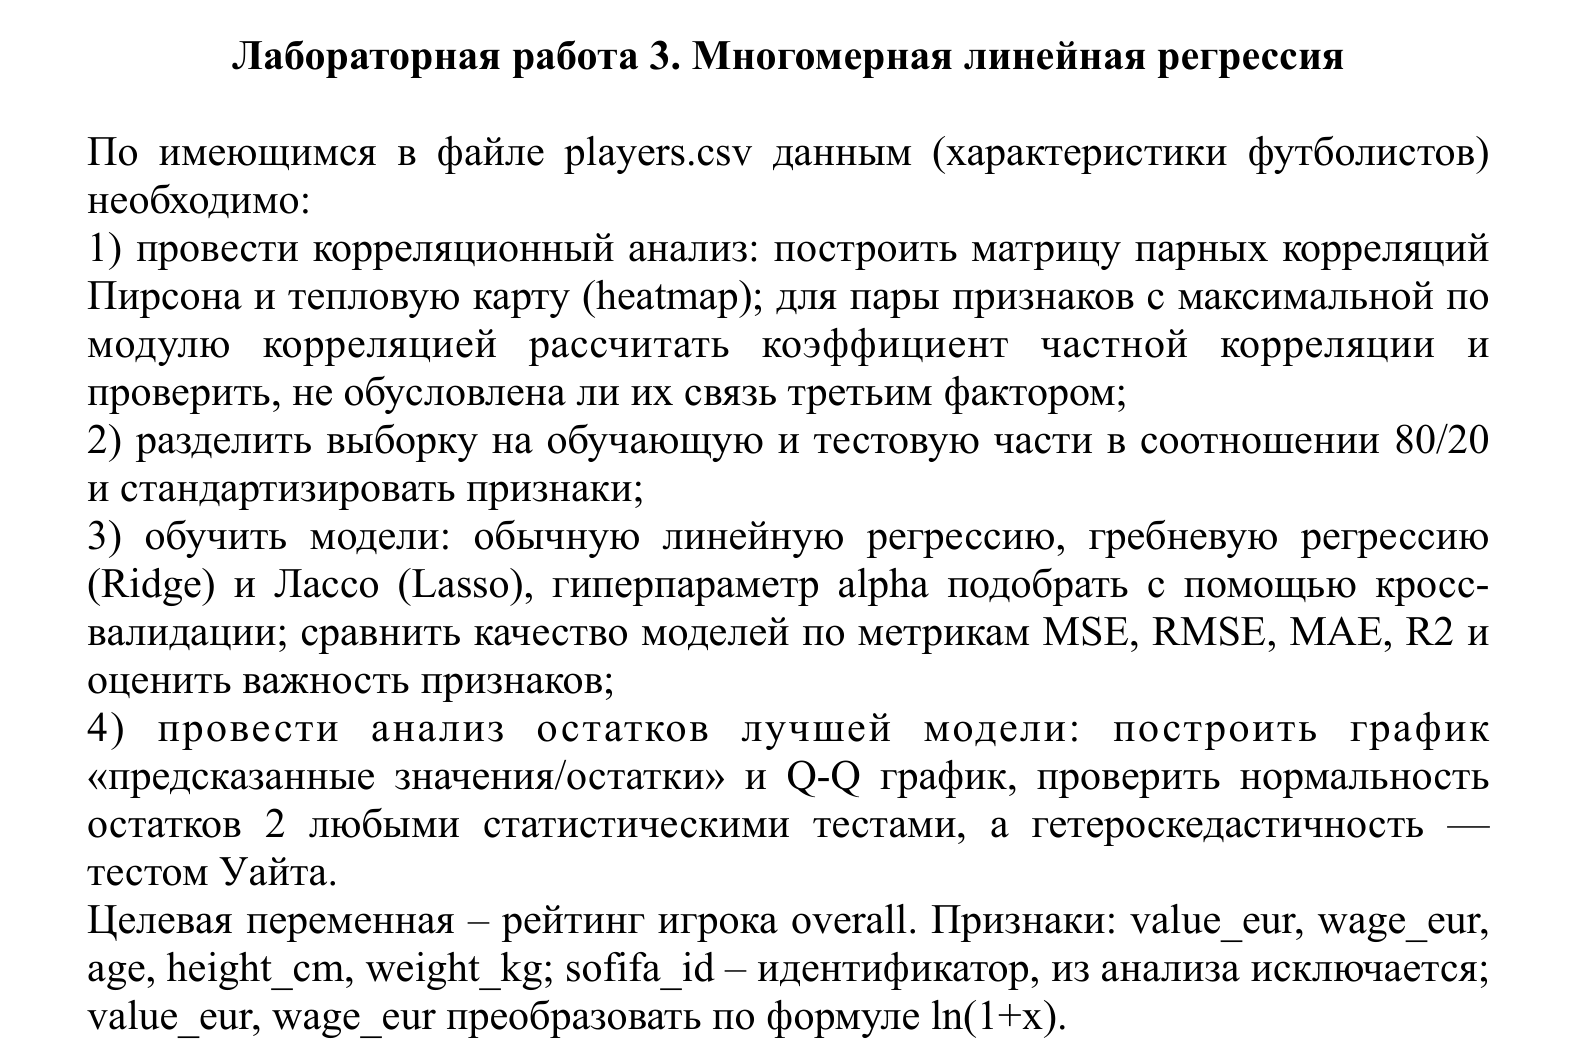

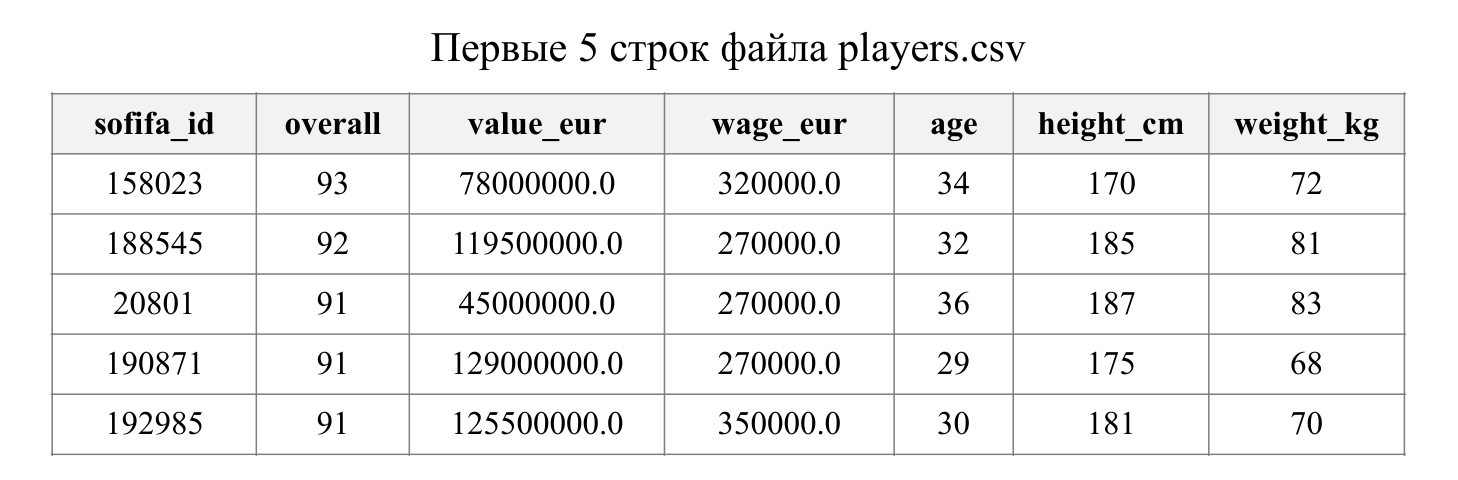

Мой Вариант: 22 mod 3 = 1

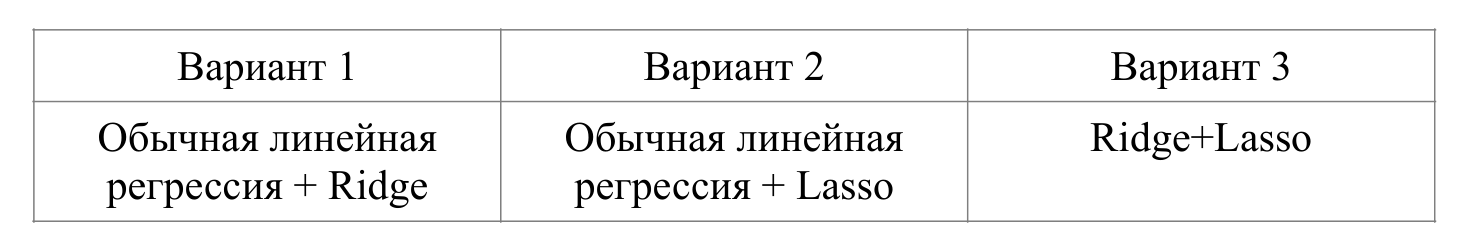

обычная линейная регрессия + Ridge

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_white
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

warnings.filterwarnings('ignore')  # numpy на маке спамит warning'ами в matmul

df = pd.read_csv('players.csv', index_col=0)
df.head()

,sofifa_id,overall,value_eur,wage_eur,age,height_cm,weight_kg
0,158023,93,78000000.0,320000.0,34,170,72
1,188545,92,119500000.0,270000.0,32,185,81
2,20801,91,45000000.0,270000.0,36,187,83
3,190871,91,129000000.0,270000.0,29,175,68
4,192985,91,125500000.0,350000.0,30,181,70


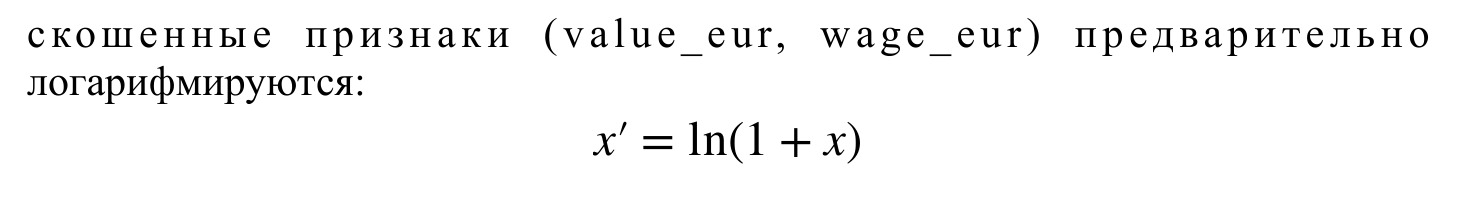

In [2]:
# sofifa_id - просто идентификатор, убираем
data = df.drop(columns='sofifa_id')

# ln(1+x)
data['value_eur'] = np.log1p(data['value_eur'])
data['wage_eur'] = np.log1p(data['wage_eur'])

target = 'overall'
features = ['value_eur', 'wage_eur', 'age', 'height_cm', 'weight_kg']
data.head()

,overall,value_eur,wage_eur,age,height_cm,weight_kg
0,93,18.172219,12.676079,34,170,72
1,92,18.598827,12.506181,32,185,81
2,91,17.622173,12.506181,36,187,83
3,91,18.675323,12.506181,29,175,68
4,91,18.647816,12.765691,30,181,70


# Пункт 1

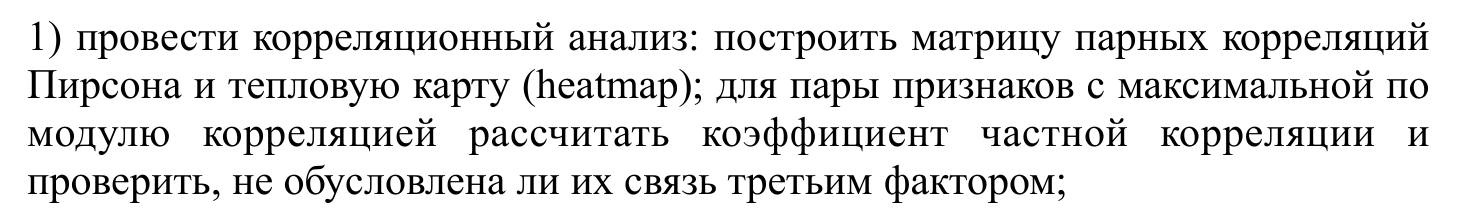

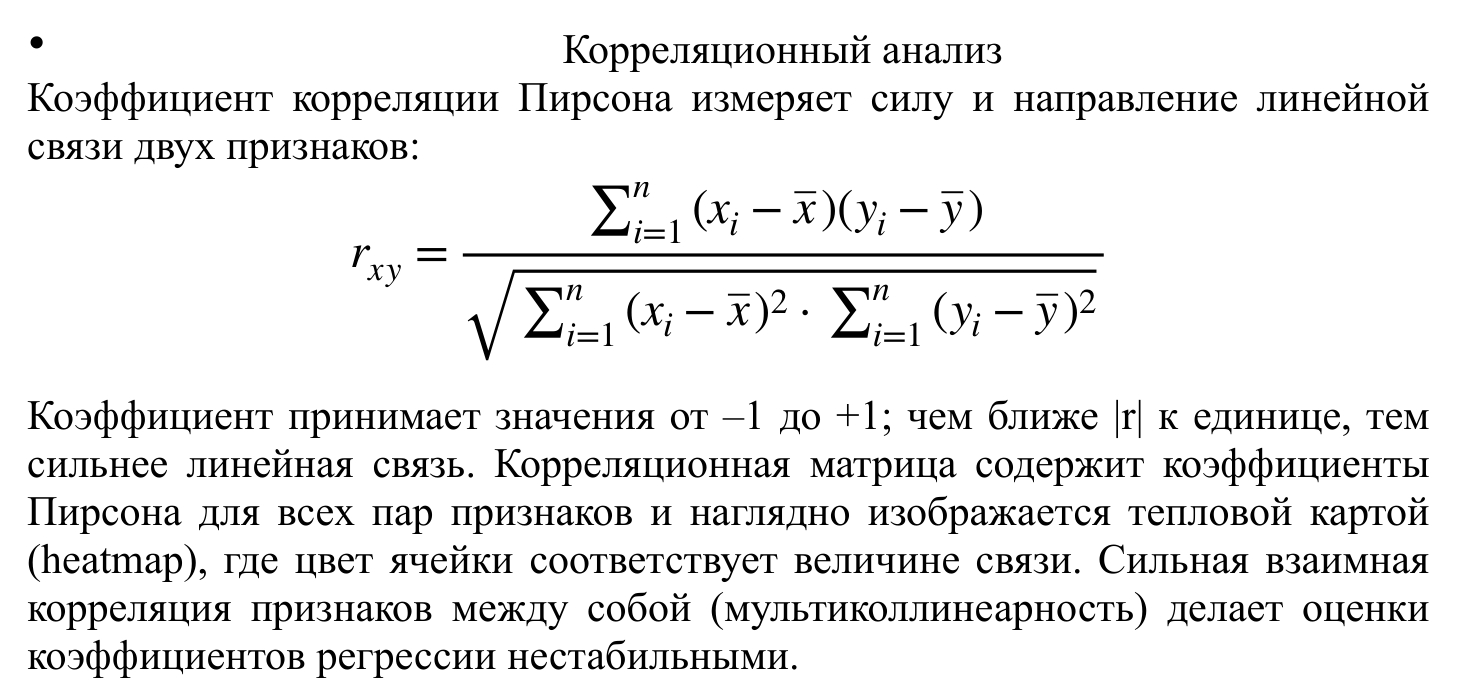

In [3]:
# коэффициент пирсона по формуле
def pearson(x, y):
    dx, dy = x - x.mean(), y - y.mean()
    return np.sum(dx * dy) / np.sqrt(np.sum(dx ** 2) * np.sum(dy ** 2))

# матрица парных корреляций
cols = [target] + features
corr = pd.DataFrame({a: [pearson(data[a], data[b]) for b in cols] for a in cols}, index=cols)
corr.round(3)

,overall,value_eur,wage_eur,age,height_cm,weight_kg
overall,1.000,0.887,0.783,0.461,0.042,0.150
value_eur,0.887,1.000,0.754,0.041,-0.018,0.028
wage_eur,0.783,0.754,1.000,0.288,0.050,0.098
age,0.461,0.041,0.288,1.000,0.083,0.240
height_cm,0.042,-0.018,0.050,0.083,1.000,0.765
weight_kg,0.150,0.028,0.098,0.240,0.765,1.000


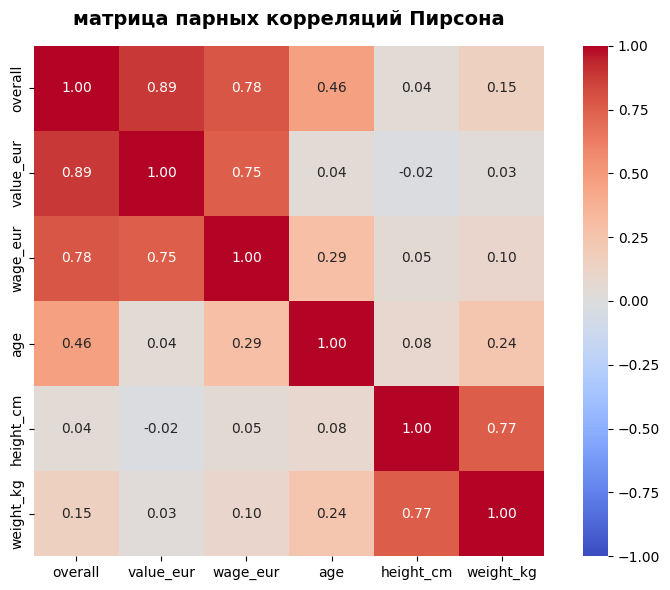

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('матрица парных корреляций Пирсона', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [5]:
# пары признаков по убыванию |r| (overall не берем, он целевая переменная)
pairs = sorted(combinations(features, 2), key=lambda p: abs(corr.loc[p[0], p[1]]), reverse=True)

for a, b in pairs[:3]:
    print(f"{a} - {b}: r = {corr.loc[a, b]:.3f}")

pair_x, pair_y = pairs[0]

height_cm - weight_kg: r = 0.765
value_eur - wage_eur: r = 0.754
wage_eur - age: r = 0.288


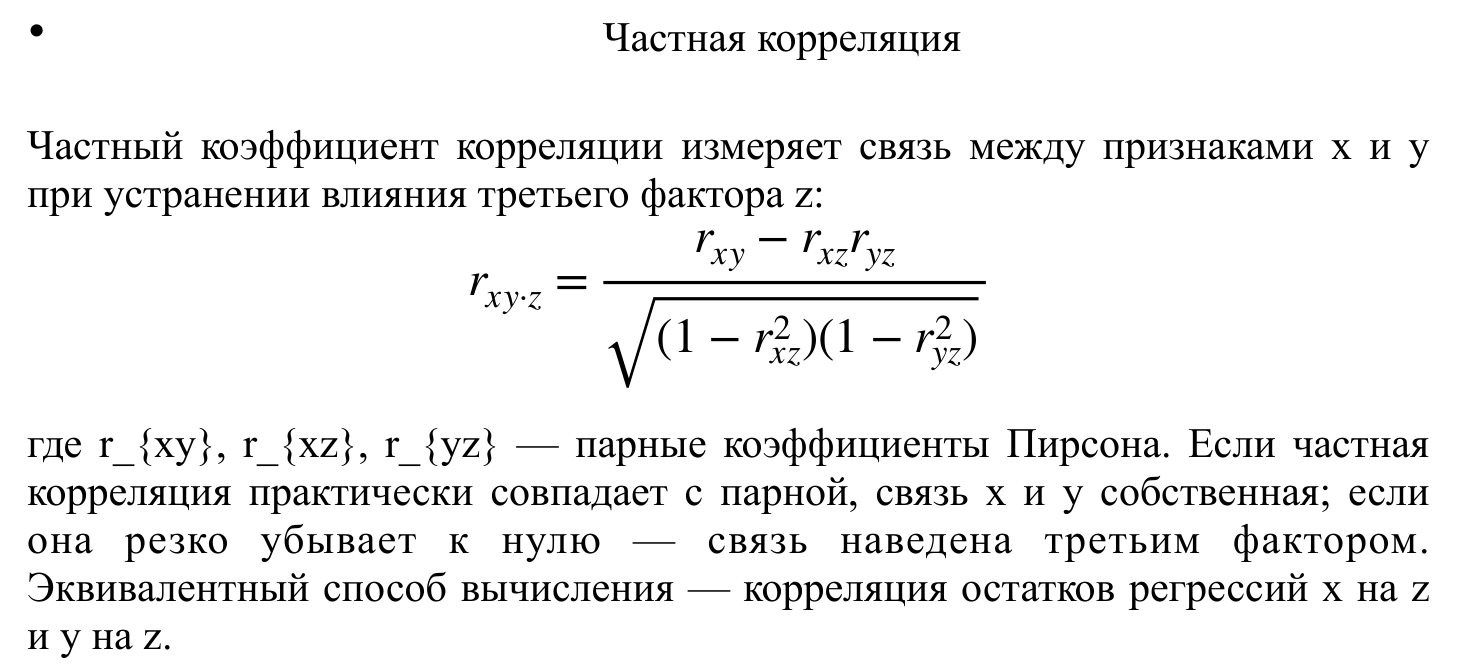

In [6]:
# частная корреляция по формуле
def partial_corr(x, y, z):
    rxy, rxz, ryz = corr.loc[x, y], corr.loc[x, z], corr.loc[y, z]
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))

# то же через остатки регрессий x на z и y на z
def partial_corr_resid(x, y, z):
    Z = data[[z]]
    ex = data[x] - LinearRegression().fit(Z, data[x]).predict(Z)
    ey = data[y] - LinearRegression().fit(Z, data[y]).predict(Z)
    return pearson(ex, ey)

# третьим фактором z по очереди пробуем все остальные переменные
others = [c for c in cols if c not in (pair_x, pair_y)]
partial = pd.DataFrame({
    'по формуле': [partial_corr(pair_x, pair_y, z) for z in others],
    'через остатки': [partial_corr_resid(pair_x, pair_y, z) for z in others],
}, index=others)

print(f"парная корреляция {pair_x} - {pair_y}: {corr.loc[pair_x, pair_y]:.3f}")
print("частная корреляция при z:")
partial.round(3)

парная корреляция height_cm - weight_kg: 0.765
частная корреляция при z:


,по формуле,через остатки
overall,0.768,0.768
value_eur,0.766,0.766
wage_eur,0.765,0.765
age,0.770,0.770


частная корреляция при любом третьем факторе z почти равна парной (0.77) — связь роста и веса собственная, третьим фактором не обусловлена

# Пункт 2

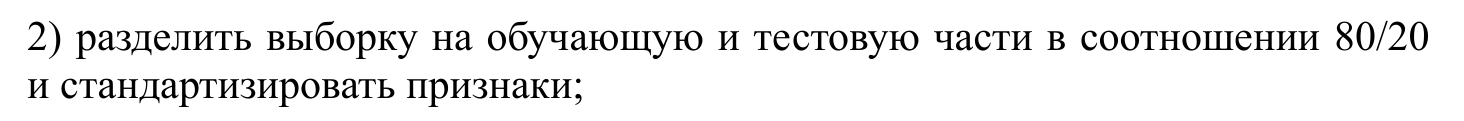

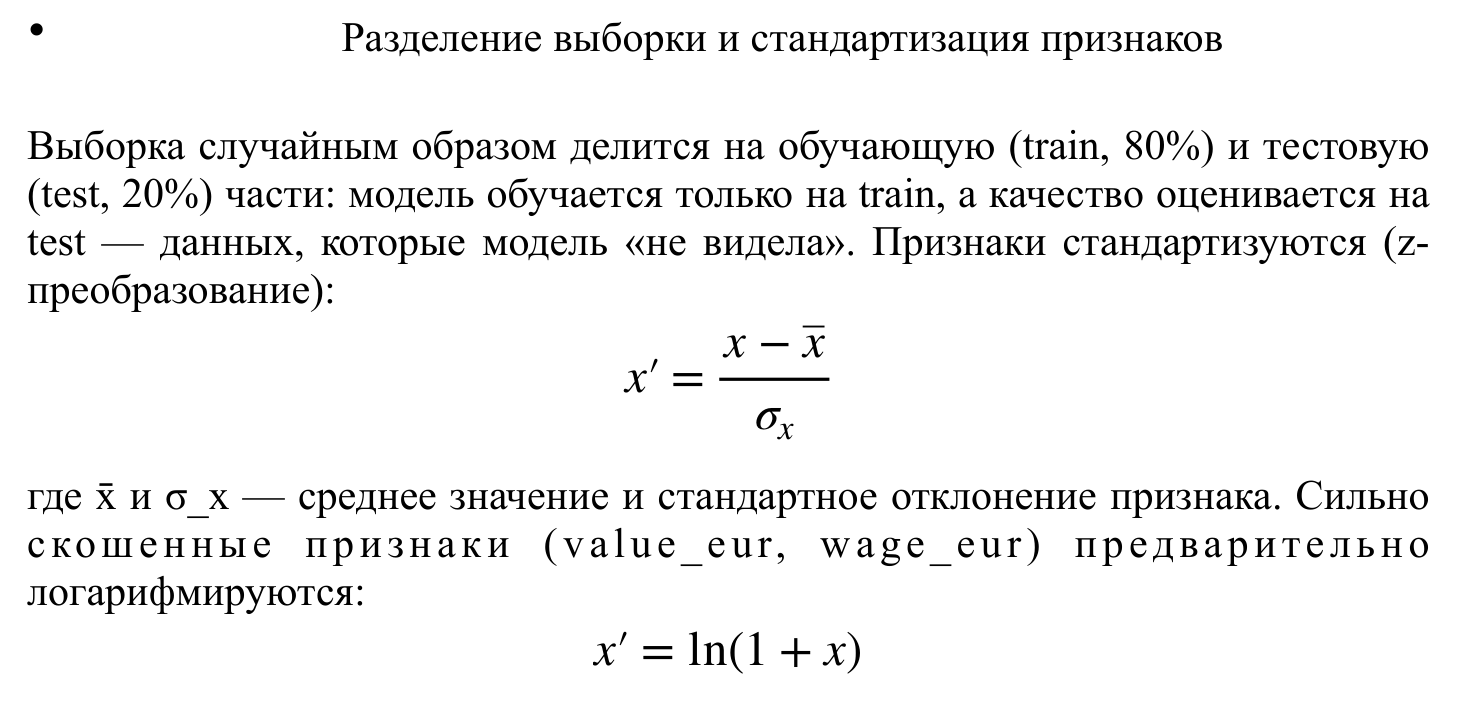

In [7]:
X = data[features]
y = data[target]

# 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# стандартизация: среднее и std берем по train, применяем и к train, и к test
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=features, index=X_test.index)

print(f"train: {len(X_train)}, test: {len(X_test)}")
print("среднее в train:", np.abs(X_train_s.mean()).round(3).values)
print("std в train    :", X_train_s.std(ddof=0).round(3).values)

train: 15332, test: 3833
среднее в train: [0. 0. 0. 0. 0.]
std в train    : [1. 1. 1. 1. 1.]


# Пункт 3

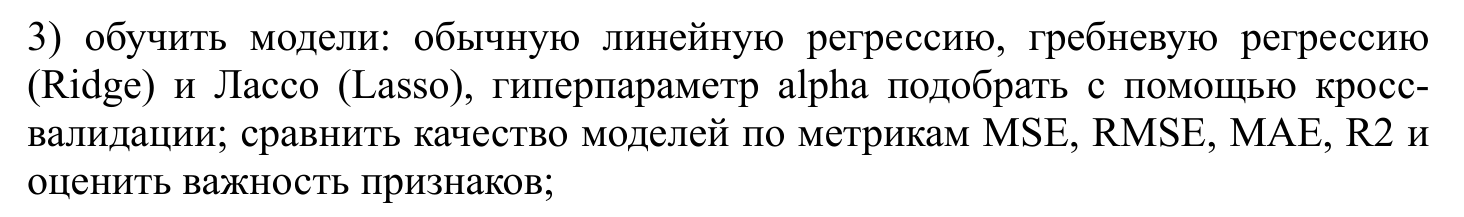

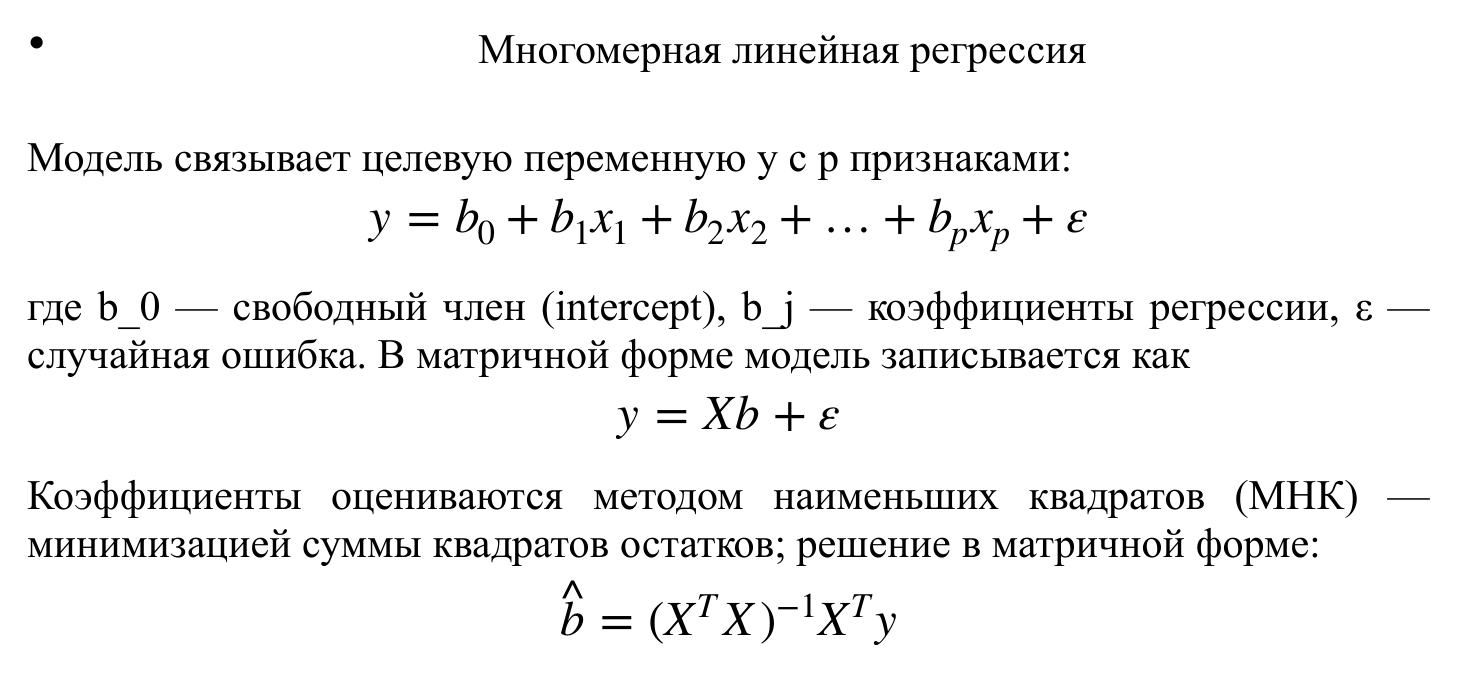

In [8]:
# обычная линейная регрессия
ols = LinearRegression().fit(X_train_s, y_train)

# то же по формуле из теории b = (XT X)^-1 XT y, первый столбец из единиц под b0
Xb = np.c_[np.ones(len(X_train_s)), X_train_s]
b = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_train.values)

print(f"b0: по формуле {b[0]:.4f}, sklearn {ols.intercept_:.4f}")
print("остальные коэффициенты совпадают:", np.allclose(b[1:], ols.coef_))

b0: по формуле 65.7442, sklearn 65.7442
остальные коэффициенты совпадают: True


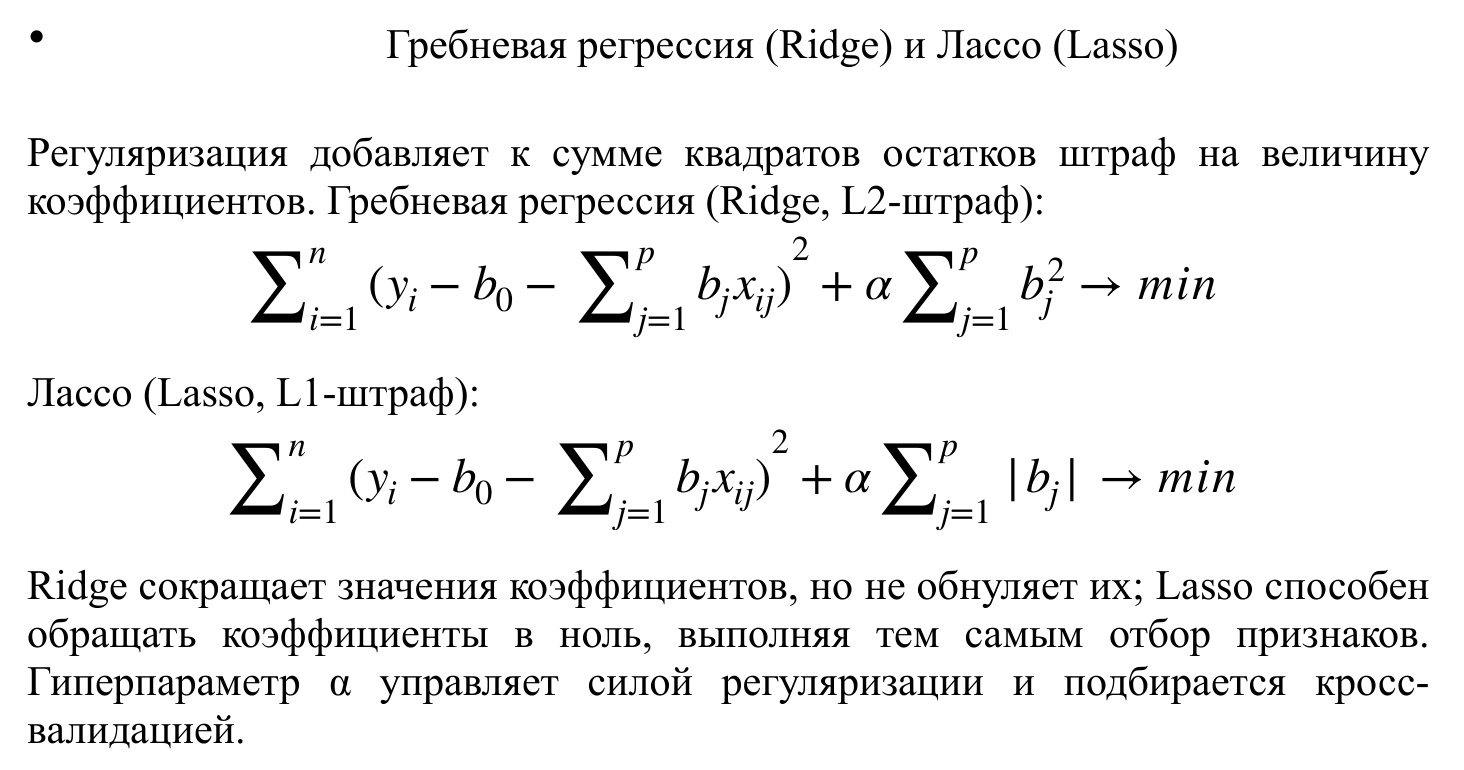

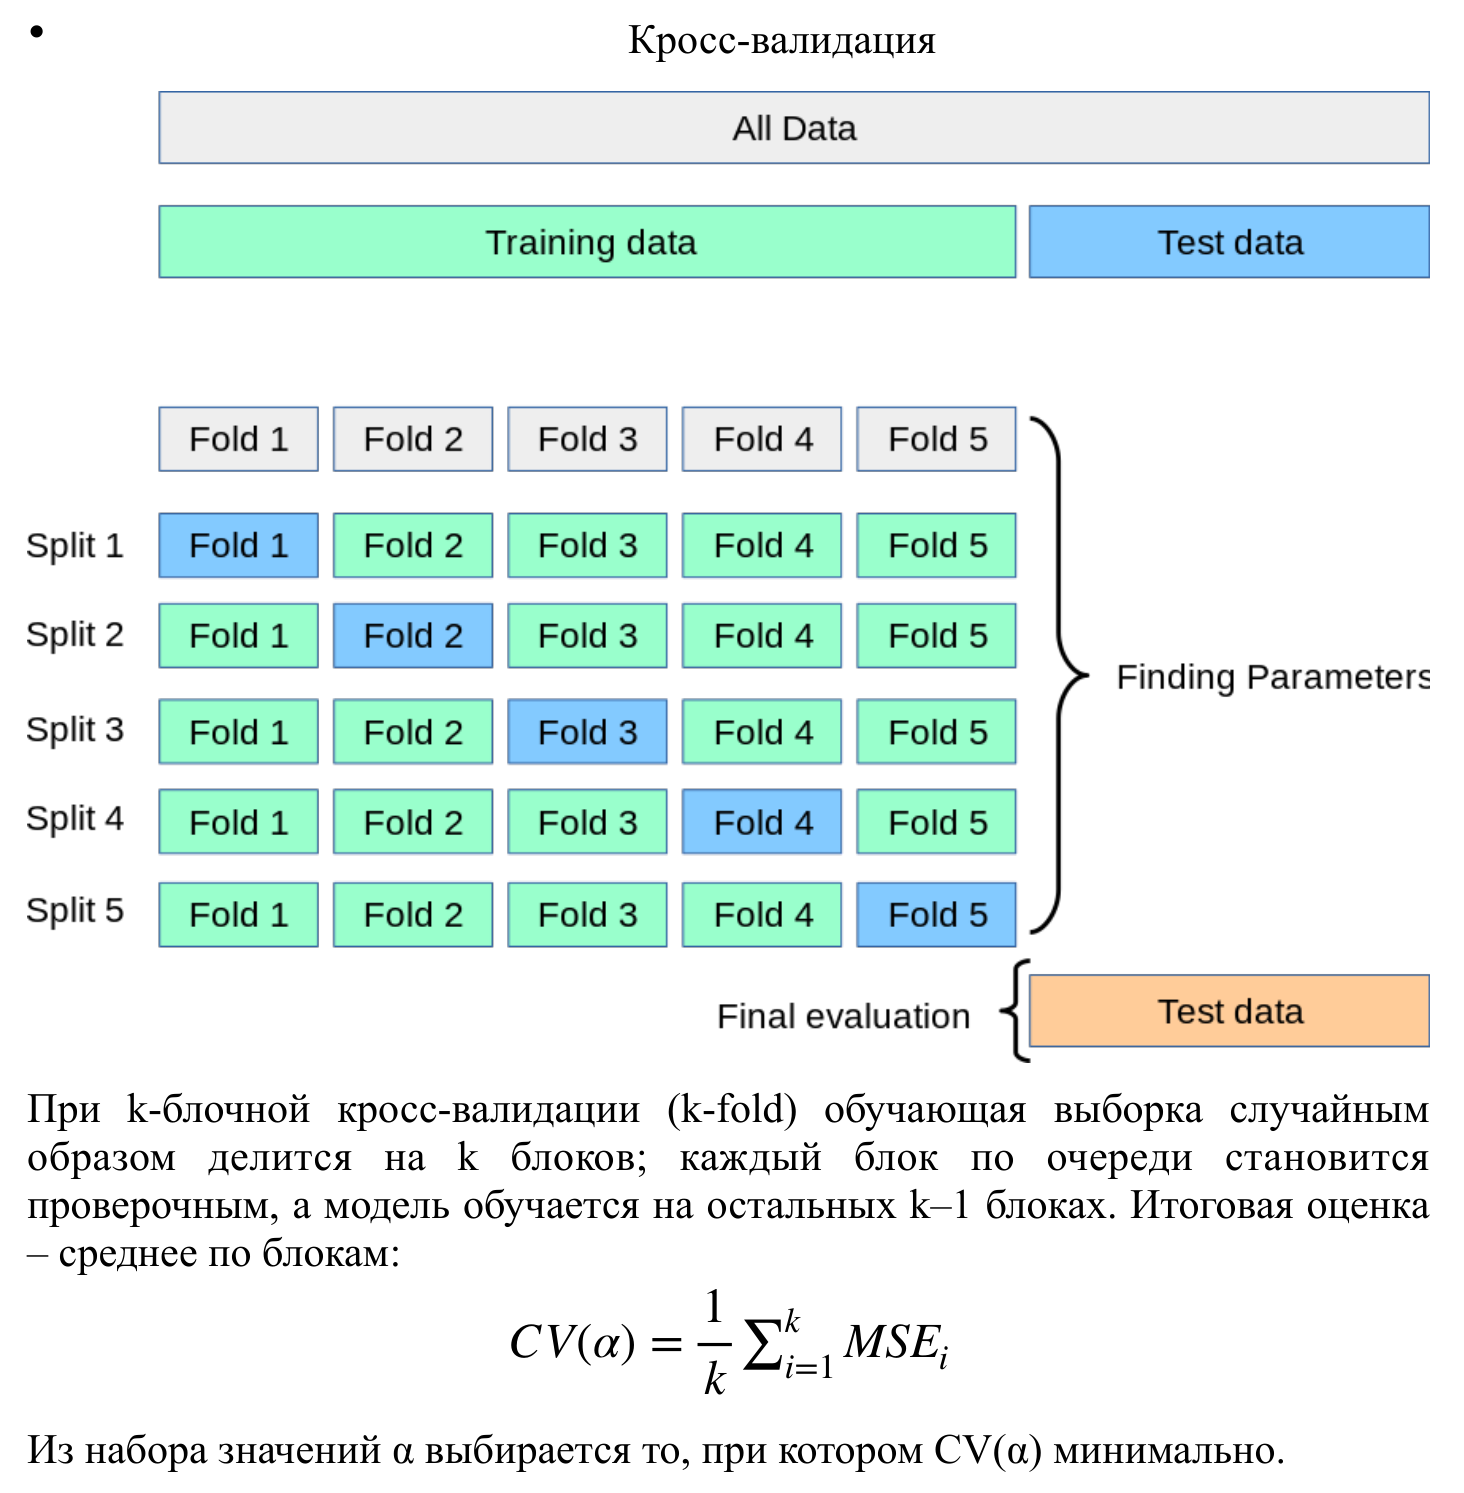

лучший alpha: 0.0010, CV mse: 1.5266


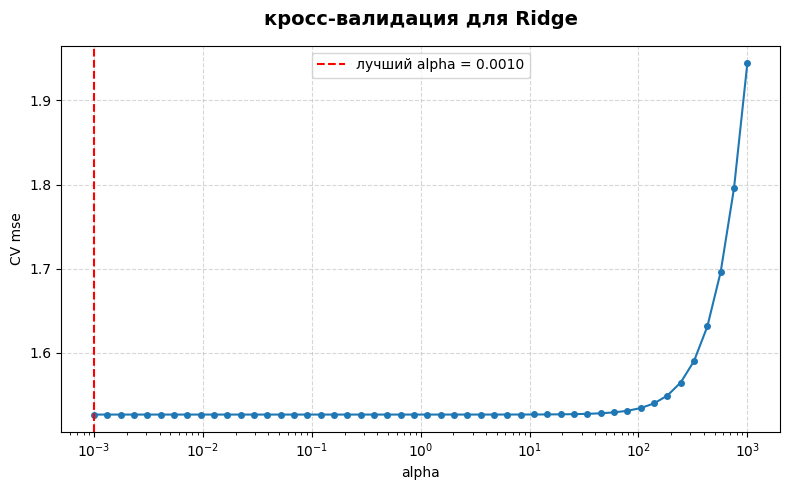

In [9]:
# сетка alpha и 5-блочная кросс-валидация
alphas = np.logspace(-3, 3, 50)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# CV(alpha) = средний mse по блокам
cv_mse = [
    -cross_val_score(Ridge(alpha=a), X_train_s, y_train, cv=kf, scoring='neg_mean_squared_error').mean()
    for a in alphas
]

best_alpha = alphas[np.argmin(cv_mse)]
print(f"лучший alpha: {best_alpha:.4f}, CV mse: {min(cv_mse):.4f}")

ridge = Ridge(alpha=best_alpha).fit(X_train_s, y_train)

plt.figure(figsize=(8, 5))
plt.semilogx(alphas, cv_mse, marker='o', markersize=4)
plt.axvline(best_alpha, color='red', linestyle='--', label=f'лучший alpha = {best_alpha:.4f}')
plt.title('кросс-валидация для Ridge', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('alpha')
plt.ylabel('CV mse')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

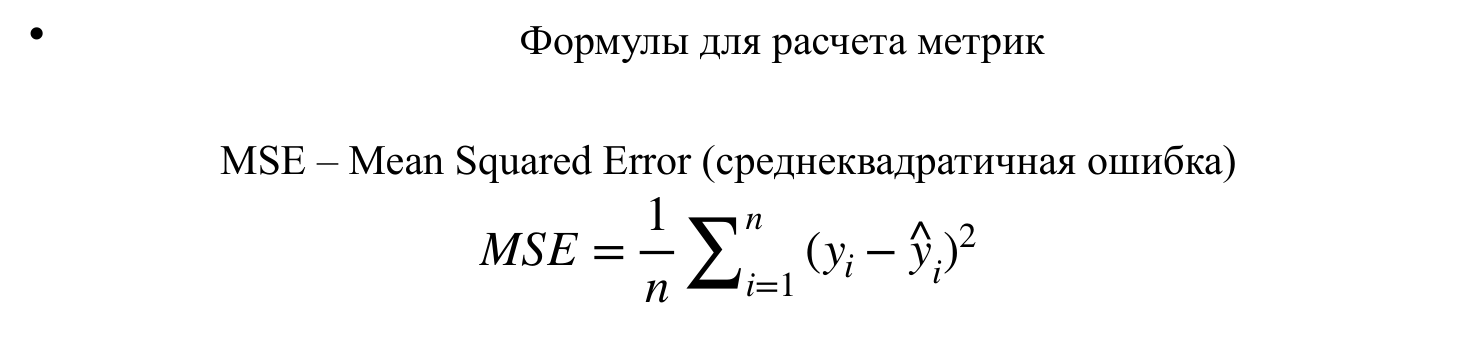

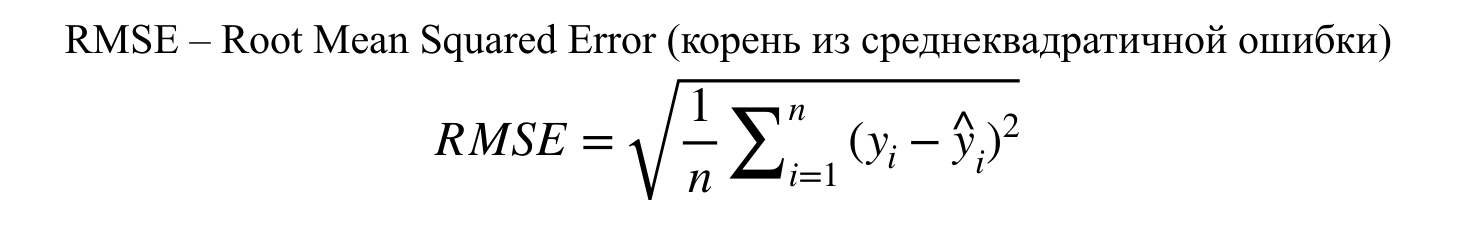

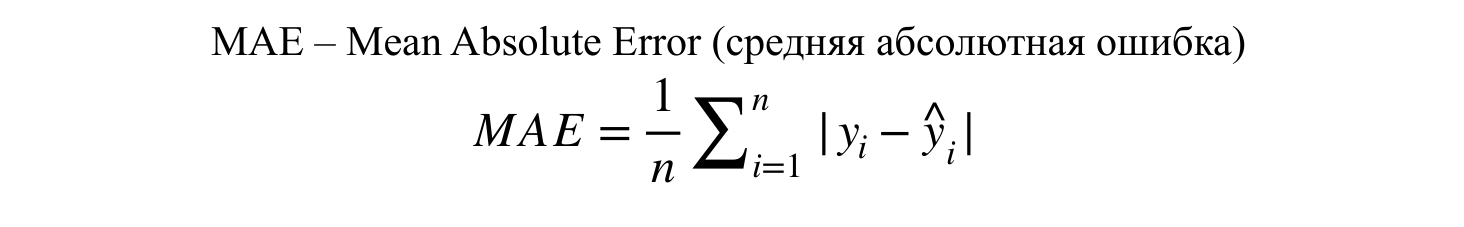

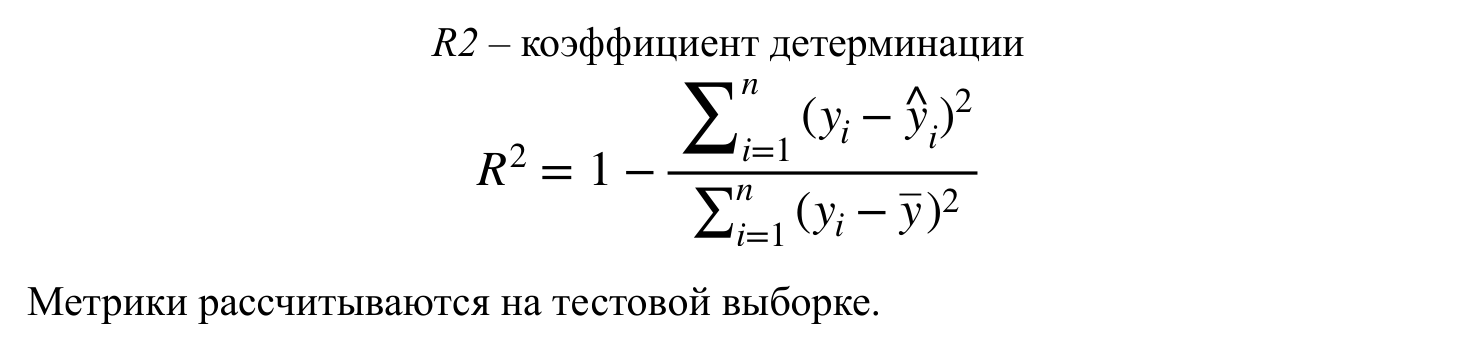

In [10]:
def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)

def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))

def mae(y, y_pred):
    return np.mean(np.abs(y - y_pred))

def r2(y, y_pred):
    return 1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2)

# метрики на тесте
models = {'линейная регрессия': ols, 'Ridge': ridge}
preds = {name: m.predict(X_test_s) for name, m in models.items()}

metrics = pd.DataFrame({
    name: [mse(y_test, p), rmse(y_test, p), mae(y_test, p), r2(y_test, p)]
    for name, p in preds.items()
}, index=['MSE', 'RMSE', 'MAE', 'R2']).T

metrics.round(4)

,MSE,RMSE,MAE,R2
линейная регрессия,1.5292,1.2366,0.9036,0.967
Ridge,1.5292,1.2366,0.9036,0.967


- метрики у обеих моделей одинаковые: MSE = 1.53, RMSE = 1.24, MAE = 0.90, R2 = 0.967
- лучший alpha для Ridge — минимальный из сетки (0.001): с ростом alpha ошибка кросс-валидации не уменьшается, поэтому Ridge получился таким же, как обычная регрессия

           линейная регрессия   Ridge
value_eur              5.9284  5.9284
age                    2.8729  2.8729
weight_kg              0.1258  0.1258
wage_eur               0.0950  0.0950
height_cm              0.0411  0.0411


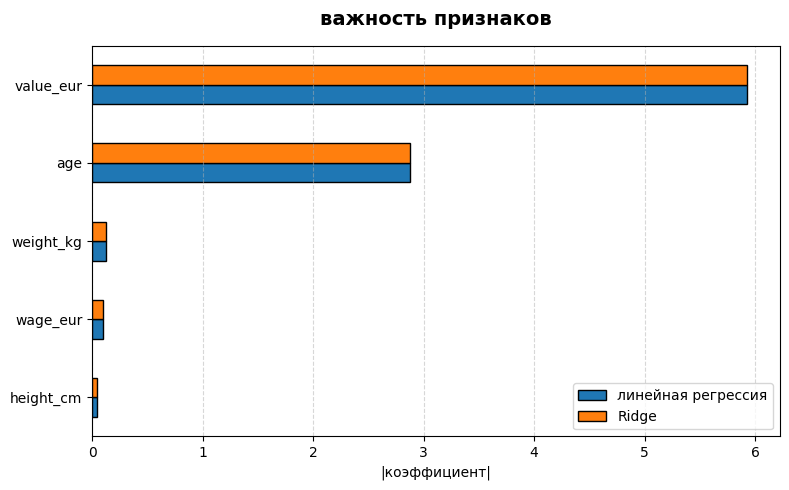

In [11]:
# признаки стандартизованы, поэтому коэффициенты можно сравнивать между собой
coefs = pd.DataFrame({'линейная регрессия': ols.coef_, 'Ridge': ridge.coef_}, index=features)
coefs = coefs.loc[coefs['линейная регрессия'].abs().sort_values(ascending=False).index]
print(coefs.round(4))

# важность признака - модуль коэффициента
coefs.abs().iloc[::-1].plot.barh(figsize=(8, 5), edgecolor='black')
plt.title('важность признаков', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('|коэффициент|')
plt.legend(loc='lower right')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

самый важный признак value_eur (5.93), следом age (2.87); у weight_kg, wage_eur и height_cm коэффициенты меньше 0.15

# Пункт 4

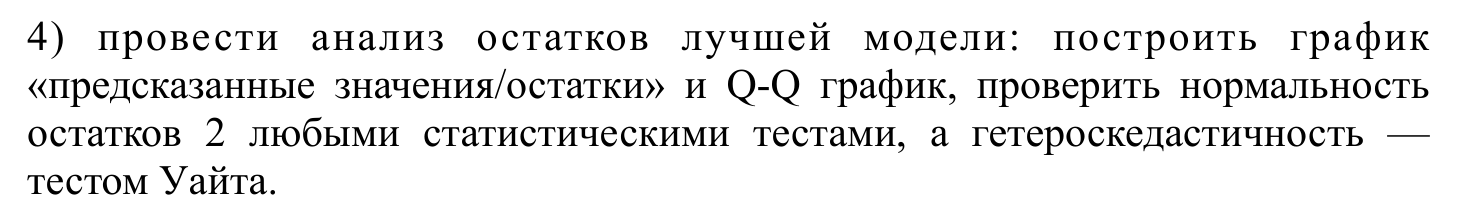

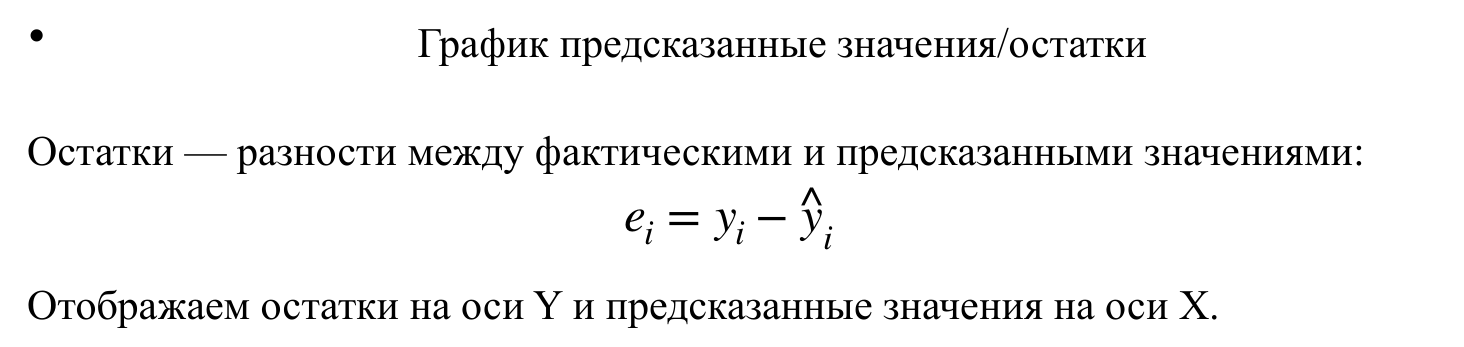

Q-Q график строится так:

- остатки сортируем по возрастанию, это ось Y
- для каждого остатка считаем долю точек до него: (номер − 0.5) / n
- по этой доле берем значение стандартного нормального распределения, это ось X
- если остатки нормальные, точки лежат на прямой
- где точки уходят от прямой, там хвосты тяжелее или легче нормальных

лучшая модель: линейная регрессия


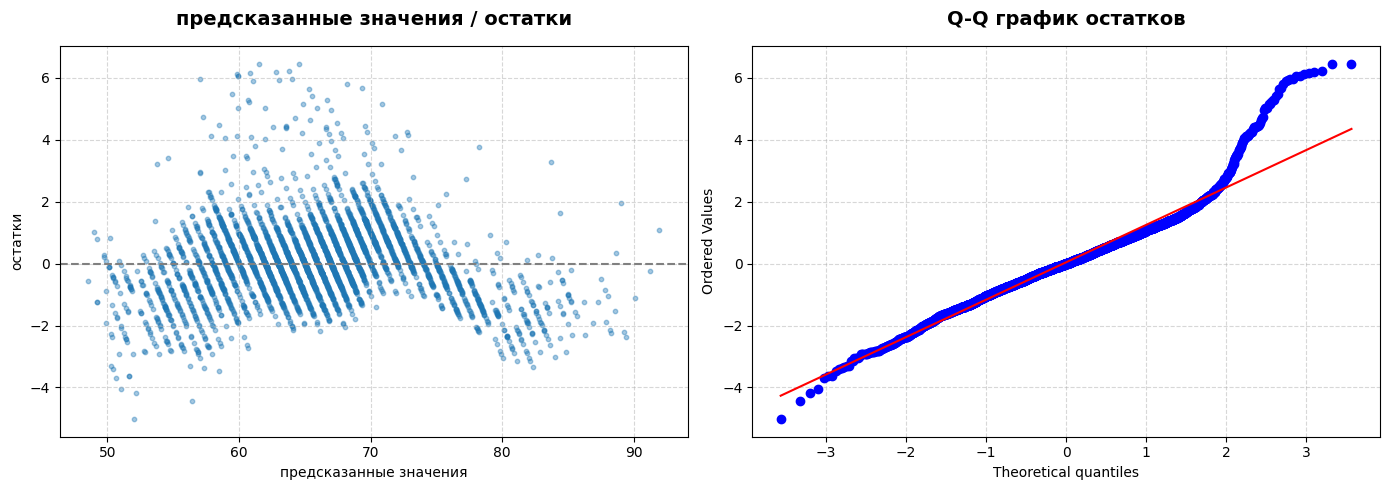

In [12]:
# лучшая модель по mse на тесте (при равенстве берем обычную)
best_name = metrics['MSE'].round(4).idxmin()
best_pred = preds[best_name]
print(f"лучшая модель: {best_name}")

# остатки на тесте
resid = y_test.values - best_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# предсказанные значения / остатки
axes[0].scatter(best_pred, resid, alpha=0.4, s=10)
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title('предсказанные значения / остатки', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('предсказанные значения')
axes[0].set_ylabel('остатки')
axes[0].grid(True, linestyle='--', alpha=0.5)

# q-q график
stats.probplot(resid, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q график остатков', fontsize=14, fontweight='bold', pad=15)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

- остатки не просто шум вокруг нуля: в середине они в основном выше нуля, по краям ниже
- разброс остатков в разных частях графика разный
- на Q-Q графике в центре точки лежат на прямой, а правый хвост уходит вверх
    - большие положительные остатки встречаются чаще и больше, чем у нормального
    - то есть иногда модель сильно занижает рейтинг: реальный выше предсказанного, до +6
    - значит, остатки не нормальные, тесты ниже это проверяют
- диагональные полосы на графике из-за того, что overall целое число

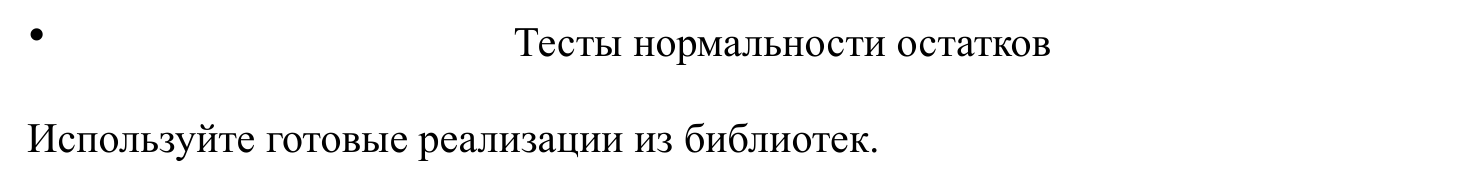

- тест нормальности проверяет, похожи ли остатки на нормальное распределение; h0: остатки нормальные
- p < 0.05 — h0 отвергаем (не нормальные), p > 0.05 — отвергнуть нечем
- Шапиро-Уилк сравнивает отсортированные остатки с нормальными; W от 0 до 1, чем ближе к 1, тем ближе к нормальному
- Харке-Бера считается по асимметрии и эксцессу; у нормального они равны 0, чем больше статистика, тем сильнее отличие
- асимметрия: 0 — симметрично, больше 0 — хвост вправо, меньше 0 — хвост влево
- эксцесс: 0 — как у нормального, больше 0 — хвосты тяжелее, меньше 0 — хвосты легче

In [13]:
# h0 - остатки нормальные, при p < 0.05 отвергаем
sw_stat, sw_p = stats.shapiro(resid)
jb_stat, jb_p = stats.jarque_bera(resid)

print(f"Шапиро-Уилк: stat = {sw_stat:.4f}, p = {sw_p:.3g}")
print(f"Харке-Бера : stat = {jb_stat:.1f}, p = {jb_p:.3g}")
print(f"асимметрия остатков: {stats.skew(resid):.3f}, эксцесс: {stats.kurtosis(resid):.3f}")

Шапиро-Уилк: stat = 0.9553, p = 9.08e-33
Харке-Бера : stat = 2114.3, p = 0
асимметрия остатков: 0.780, эксцесс: 3.287


- p-value у обоих тестов меньше 0.05, нормальность остатков отвергаем
- асимметрия 0.78 (скос вправо), эксцесс 3.29 (хвосты тяжелее нормальных)

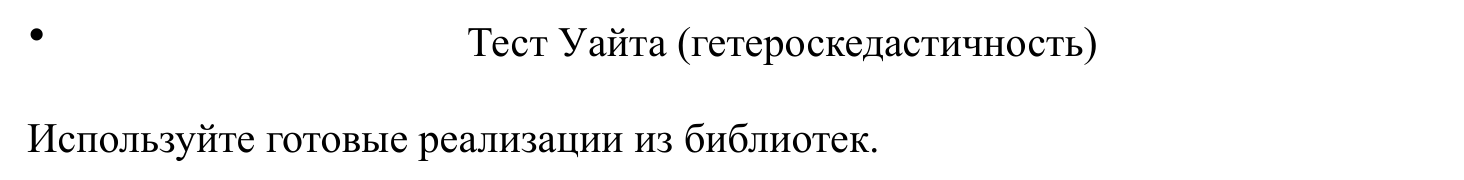

- гетероскедастичность — разброс остатков непостоянный; гомоскедастичность — постоянный
- тест Уайта проверяет, зависит ли размер ошибки (квадрат остатка) от признаков
- h0: дисперсия постоянная; p < 0.05 — отвергаем, гетероскедастичность есть
- чем больше статистика LM, тем сильнее зависимость ошибки от признаков

In [14]:
# h0 - дисперсия остатков постоянная, при p < 0.05 отвергаем
exog = sm.add_constant(X_test_s)
lm_stat, lm_p, f_stat, f_p = het_white(resid, exog)

print(f"LM-статистика: {lm_stat:.2f}, p = {lm_p:.3g}")
print(f"F-статистика : {f_stat:.2f}, p = {f_p:.3g}")

LM-статистика: 1094.35, p = 2.85e-219
F-статистика : 76.16, p = 6.24e-260


p-value теста Уайта меньше 0.05 — гетероскедастичность есть, дисперсия остатков непостоянна

# Выводы

- самая сильная связь между признаками — рост и вес (r = 0.77), частная корреляция при любом третьем факторе тоже около 0.77, значит связь собственная
- обычная линейная регрессия и Ridge на тесте дают одинаковые метрики: RMSE = 1.24, MAE = 0.90, R2 = 0.967
- alpha для Ridge по кросс-валидации минимальный из сетки, штраф качество не улучшает
- важнее всего value_eur, затем age, у остальных трёх признаков коэффициенты близки к нулю
- остатки не нормальные: у обоих тестов p < 0.05, правый хвост тяжёлый
- тест Уайта: p < 0.05, гетероскедастичность есть
- на графике остатков видна дуга: по краям остатки ниже нуля, в середине выше